# 1) Write a Python script using pandas and scikit-learn to load a dataset, perform a 70/30 train/test split, and apply standard scaling (StandardScaler) to the feature columns.

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 1: Create a sample dataset
data = {
    "Age": [22, 25, 30, 35, 40, 45, 50, 28, 33, 38,
            42, 48, 26, 31, 37, 44, 52, 29, 36, 41],
    "Salary": [20000, 25000, 30000, 35000, 40000,
               45000, 50000, 28000, 33000, 38000,
               42000, 48000, 26000, 31000, 37000,
               44000, 52000, 29000, 36000, 41000],
    "Experience": [1, 2, 4, 6, 8, 10, 12, 3, 5, 7,
                   9, 11, 2, 4, 6, 9, 13, 3, 7, 8],
    "Purchased": [0, 0, 0, 1, 1, 1, 1, 0, 1, 1,
                  1, 1, 0, 0, 1, 1, 1, 0, 1, 1]
}

df = pd.DataFrame(data)

# Step 2: Separate features and target
X = df.drop("Purchased", axis=1)
y = df["Purchased"]

# Step 3: Split into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Step 4: Apply StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Convert results back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=X_test.index
)

# Step 6: Display results
print("Original Dataset:")
print(df.head())

print("\nTraining Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nScaled Training Features:")
print(X_train_scaled)

print("\nScaled Testing Features:")
print(X_test_scaled)

print("\nTraining Target Values:")
print(y_train.values)

print("\nTesting Target Values:")
print(y_test.values)

print("\nSuccess! Train/test split and scaling completed.")


Original Dataset:
   Age  Salary  Experience  Purchased
0   22   20000           1          0
1   25   25000           2          0
2   30   30000           4          0
3   35   35000           6          1
4   40   40000           8          1

Training Data Shape: (14, 3)
Testing Data Shape: (6, 3)

Scaled Training Features:
         Age    Salary  Experience
11  1.272768  1.272768    1.203870
3  -0.405810 -0.405810   -0.356702
18 -0.276689 -0.276689   -0.044588
16  1.789254  1.789254    1.828100
13 -0.922296 -0.922296   -0.980932
2  -1.051417 -1.051417   -0.980932
9  -0.018446 -0.018446   -0.044588
19  0.368918  0.368918    0.267527
4   0.239797  0.239797    0.267527
12 -1.567903 -1.567903   -1.605161
7  -1.309660 -1.309660   -1.293046
10  0.498040  0.498040    0.579641
14 -0.147567 -0.147567   -0.356702
6   1.531011  1.531011    1.515985

Scaled Testing Features:
         Age    Salary  Experience
0  -2.084388 -2.342631   -1.917275
17 -1.180539 -1.180539   -1.293046
15  0.756283  

# 2) Using matplotlib and seaborn, write a function that takes a pandas DataFrame and a column name as input, and plots both a boxplot and a scatter plot to visually identify outliers and distribution patterns.

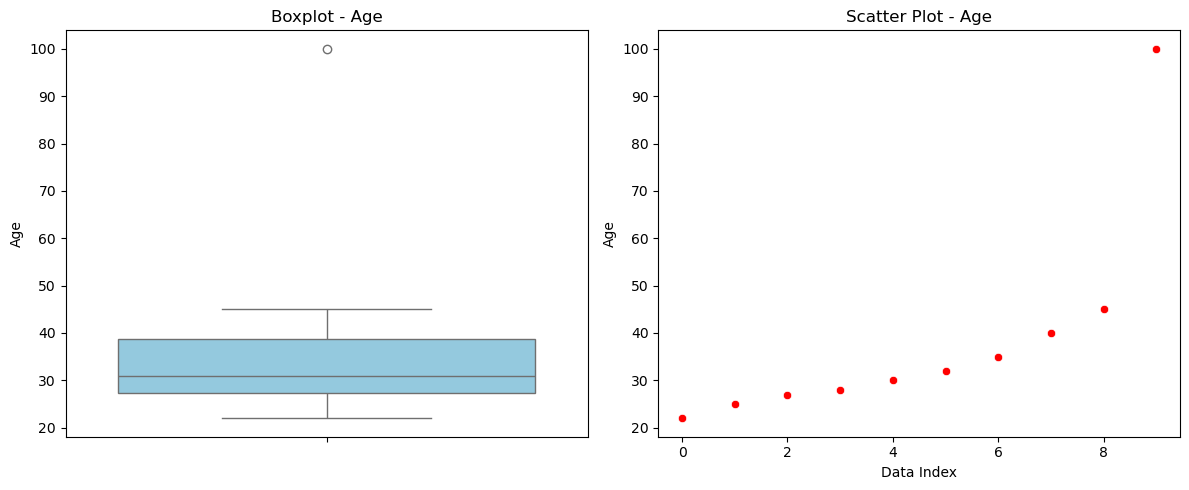

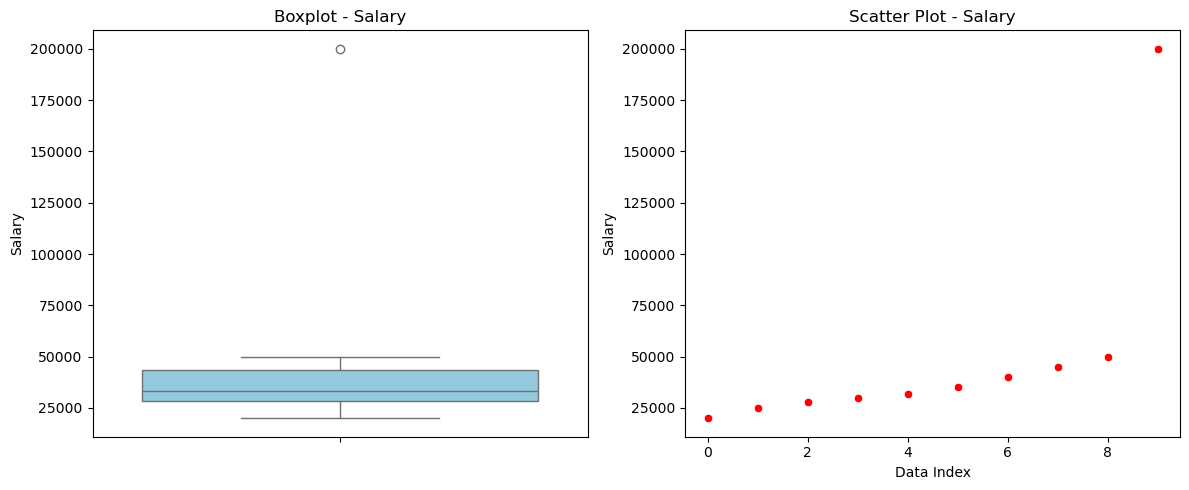

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Function to plot boxplot and scatter plot
def plot_outliers(df, column_name):

    # Check whether the column exists
    if column_name not in df.columns:
        print("Error: Column not found in the DataFrame.")
        return

    # Check whether the column contains numeric data
    if not pd.api.types.is_numeric_dtype(df[column_name]):
        print("Error: Please select a numeric column.")
        return

    # Remove missing values for plotting
    data = df[column_name].dropna()

    if data.empty:
        print("Error: The selected column has no valid data.")
        return

    # Create two plots side by side
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Boxplot to identify outliers
    sns.boxplot(y=data, ax=axes[0], color="skyblue")
    axes[0].set_title("Boxplot - " + column_name)
    axes[0].set_ylabel(column_name)

    # Scatter plot to visualize data distribution
    sns.scatterplot(x=range(len(data)), y=data, ax=axes[1],
                    color="red")
    axes[1].set_title("Scatter Plot - " + column_name)
    axes[1].set_xlabel("Data Index")
    axes[1].set_ylabel(column_name)

    # Display both plots
    plt.tight_layout()
    plt.show()


# Example dataset
df = pd.DataFrame({
    "Age": [22, 25, 27, 28, 30, 32, 35, 40, 45, 100],
    "Salary": [20000, 25000, 28000, 30000, 32000,
               35000, 40000, 45000, 50000, 200000]
})

# Call the function
plot_outliers(df, "Age")
plot_outliers(df, "Salary")

# 3) Implement a linear regression model using scikit-learn's LinearRegression on a housing dataset. Calculate and print the Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R' score on the test set.

In [5]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Step 1: Load the housing dataset
housing = fetch_california_housing()

X = housing.data
y = housing.target

# Step 2: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Step 3: Create the Linear Regression model
model = LinearRegression()

# Step 4: Train the model
model.fit(X_train, y_train)

# Step 5: Make predictions on the test set
y_pred = model.predict(X_test)

# Step 6: Calculate evaluation metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Step 7: Print the results
print("Linear Regression - Housing Price Prediction")
print("--------------------------------------------")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE):     {mae:.4f}")
print(f"R² Score:                      {r2:.4f}")

Linear Regression - Housing Price Prediction
--------------------------------------------
Root Mean Squared Error (RMSE): 0.7284
Mean Absolute Error (MAE):     0.5272
R² Score:                      0.5958


# 4) Write a Python program to load the Iris dataset, train a LogisticRegression model, and output the predicted classes for the test dataset.

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Step 1: Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Step 2: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Step 3: Create the Logistic Regression model
model = LogisticRegression(max_iter=200)

# Step 4: Train the model
model.fit(X_train, y_train)

# Step 5: Predict classes for the test dataset
y_pred = model.predict(X_test)

# Step 6: Print predicted classes
print("Predicted Classes:")
print(y_pred)

# Step 7: Print actual classes for comparison
print("\nActual Classes:")
print(y_test)

# Step 8: Calculate and print accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Step 9: Display predicted class names
print("\nPredicted Flower Names:")
print(iris.target_names[y_pred])

Predicted Classes:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0 0 0 2 1 1 0 0]

Actual Classes:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0 0 0 2 1 1 0 0]

Model Accuracy: 100.0 %

Predicted Flower Names:
['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor' 'virginica' 'setosa'
 'setosa' 'setosa' 'setosa' 'versicolor' 'virginica' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'virginica' 'virginica' 'virginica' 'virginica' 'setosa' 'setosa'
 'setosa' 'setosa' 'versicolor' 'setosa' 'setosa' 'virginica' 'versicolor'
 'setosa' 'setosa' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'setosa']


# 5) Implement a K-Nearest Neighbors (KNN) classifier with n_neighbors=5. After training and testing the model, write the code to compute and display its confusion matrix using scikit-learn utilities.

Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Model Accuracy: 100.0 %


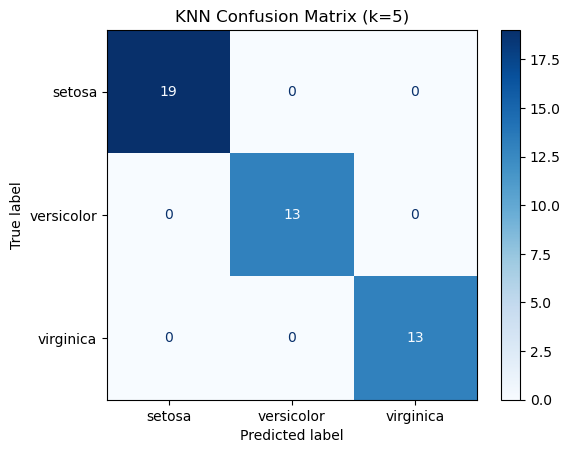

In [7]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Step 1: Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Step 2: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Step 3: Create the KNN classifier with 5 neighbors
model = KNeighborsClassifier(n_neighbors=5)

# Step 4: Train the model
model.fit(X_train, y_train)

# Step 5: Predict the test data
y_pred = model.predict(X_test)

# Step 6: Calculate and display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Step 7: Display model accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Step 8: Plot the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
display.plot(cmap="Blues")
plt.title("KNN Confusion Matrix (k=5)")
plt.show()

# 6) Write a script to compare a single Decision Tree Classifier against a Random Forest Classifier on a binary classification dataset. Print the accuracy score of both models to determine which performed better.

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Step 1: Load a binary classification dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Step 2: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Step 3: Create the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Step 4: Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

# Step 5: Train both models
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# Step 6: Make predictions
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Step 7: Calculate accuracy scores
dt_accuracy = accuracy_score(y_test, dt_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)

# Step 8: Print the results
print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

# Step 9: Compare the models
print("\nModel Comparison:")

if dt_accuracy > rf_accuracy:
    print("Decision Tree performed better.")
elif rf_accuracy > dt_accuracy:
    print("Random Forest performed better.")
else:
    print("Both models achieved the same accuracy.")

Decision Tree Accuracy: 91.81 %
Random Forest Accuracy: 93.57 %

Model Comparison:
Random Forest performed better.


# 7) Given a set of true labels and predicted labels, write code to manually calculate or use scikit-learn to extract the precision, recall, and F1-score for a specific target class without using the full classification_report.

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Step 1: Define true labels and predicted labels
y_true = [0, 1, 1, 0, 1, 0, 1, 1, 0, 1]
y_pred = [0, 1, 0, 0, 1, 1, 1, 0, 0, 1]

# Step 2: Specify the target class
target_class = 1

# Step 3: Calculate precision, recall, and F1-score
precision = precision_score(
    y_true, y_pred, pos_label=target_class, zero_division=0
)
recall = recall_score(
    y_true, y_pred, pos_label=target_class, zero_division=0
)
f1 = f1_score(
    y_true, y_pred, pos_label=target_class, zero_division=0
)

# Step 4: Display the results
print("Target Class:", target_class)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Target Class: 1
Precision: 0.8
Recall: 0.6667
F1-score: 0.7273


# 8) Implement a 5-fold cross-validation routine using KFold and cross_val_score to evaluate the stability of a Ridge regression model on a continuous target variable.

In [10]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge

# Step 1: Load a dataset with a continuous target variable
data = load_diabetes()
X = data.data
y = data.target

# Step 2: Create the Ridge Regression model
model = Ridge(alpha=1.0)

# Step 3: Define 5-fold cross-validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Step 4: Evaluate the model using cross-validation
# Negative MSE is returned because scikit-learn maximizes scores
scores = cross_val_score(
    model,
    X,
    y,
    cv=kfold,
    scoring="neg_mean_squared_error"
)

# Step 5: Convert negative MSE scores to positive MSE
mse_scores = -scores

# Step 6: Calculate RMSE for each fold
rmse_scores = np.sqrt(mse_scores)

# Step 7: Display the results
print("Ridge Regression - 5-Fold Cross-Validation")
print("------------------------------------------")

for i, rmse in enumerate(rmse_scores, start=1):
    print(f"Fold {i} RMSE: {rmse:.2f}")

print("\nMean RMSE:", round(np.mean(rmse_scores), 2))
print("Standard Deviation of RMSE:", round(np.std(rmse_scores), 2))
print("Minimum RMSE:", round(np.min(rmse_scores), 2))
print("Maximum RMSE:", round(np.max(rmse_scores), 2))

Ridge Regression - 5-Fold Cross-Validation
------------------------------------------
Fold 1 RMSE: 55.47
Fold 2 RMSE: 58.47
Fold 3 RMSE: 60.28
Fold 4 RMSE: 57.98
Fold 5 RMSE: 60.61

Mean RMSE: 58.56
Standard Deviation of RMSE: 1.85
Minimum RMSE: 55.47
Maximum RMSE: 60.61


# 9) Write a Python snippet utilizing GridSearchCV to find the optimal hyperparameters for a Random Forest Classifier. Search across _estimators (50, 100, 200)) and max_depth ([None, 10, 20]).

In [11]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Step 1: Load a classification dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Step 2: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Step 3: Create the Random Forest model
rf = RandomForestClassifier(random_state=42)

# Step 4: Define the hyperparameter grid
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20]
}

# Step 5: Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Step 6: Train and search for the best parameters
grid_search.fit(X_train, y_train)

# Step 7: Print the best hyperparameters and CV score
print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:",
      round(grid_search.best_score_ * 100, 2), "%")

# Step 8: Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Best Hyperparameters: {'max_depth': None, 'n_estimators': 100}
Best Cross-Validation Accuracy: 97.25 %
Test Accuracy: 93.57 %


# 10) Create a complete scikit-learn Pipeline that chains a MinMaxScaler preprocessing step with a LogisticRegression classifier, then fit the entire pipeline on training data and evaluate it on test data.

In [12]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Step 1: Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Step 2: Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Step 3: Create the Pipeline
pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

# Step 4: Fit the entire Pipeline on training data
pipeline.fit(X_train, y_train)

# Step 5: Predict on test data
y_pred = pipeline.predict(X_test)

# Step 6: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Pipeline Results")
print("------------------------------------")
print("Test Accuracy:", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

Logistic Regression Pipeline Results
------------------------------------
Test Accuracy: 94.74 %

Confusion Matrix:
[[ 56   8]
 [  1 106]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.88      0.93        64
      benign       0.93      0.99      0.96       107

    accuracy                           0.95       171
   macro avg       0.96      0.93      0.94       171
weighted avg       0.95      0.95      0.95       171

